# v2 analysis

Every figure and table the spec (`docs/spec.md`) lists, read from the results command's saved files. Nothing here fits a model.

Each reading's outcome is computed from the pre-registered rules in `backtest/analysis.py`, not written by hand. Statistics use the seed-averaged series, at the settings recorded in the run's `run.json`.

`RESULTS` below is the only line that changes between the rehearsal outputs and the official ones.

In [1]:
RESULTS = "results"  # rehearsal outputs: "results-rehearsal"

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))
from backtest import analysis as a
from backtest.results import ARMS, PRIMARY_PAIR
from backtest.stats import exposure_matched_benchmark

RESULTS = ROOT / RESULTS
series, trades, windows, settings = a.load(RESULTS)
run_info = json.loads((RESULTS / "run.json").read_text())
{k: run_info[k] for k in ["official_run", "git", "rows", "first_date", "last_date", "prices_sha256"]}

{'official_run': True,
 'git': 'v2-official-run',
 'rows': 1465,
 'first_date': '2019-10-01',
 'last_date': '2025-10-24',
 'prices_sha256': '31a8fa083c754b2804c295465d2bae2d0399d68f77af13f8686457c2c40a5202'}

In [2]:
CI = f"{1 - settings.ci_alpha:.0%} CI"
LABELS = {"v1_style": "headline arm: v1-style arm (v1's features inside the corrected pipeline)", "stationary_twin": "stationary twin"}
bench = a.benchmark(series)


def rows(runs, round_trip_bps=None):
    return pd.DataFrame({r: a.summary(series, trades, r, settings, round_trip_bps) for r in runs}).T


def fmt(t):
    """A summary table as readable strings. Excess return is the mean daily excess, in bps."""
    return pd.DataFrame({
        "strategy return": t.strategy_return.map("{:+.1%}".format),
        f"Sharpe [{CI}]": [f"{s:.2f} [{lo:.2f}, {hi:.2f}]" for s, (lo, hi) in zip(t.sharpe, t.sharpe_ci)],
        f"excess, bps/day [{CI}]": [f"{e * 1e4:+.2f} [{lo * 1e4:+.2f}, {hi * 1e4:+.2f}]"
                                    for e, (lo, hi) in zip(t.excess, t.excess_ci)],
        "break-even, bps round trip": t.break_even.map(lambda b: "None" if b is None else f"{b:.0f}"),
        "trades per seed": t.trades_per_seed.map("{:.1f}".format),
        "per-seed Sharpe, mean (min to max)": [f"{m:.2f} ({lo:.2f} to {hi:.2f})" for m, lo, hi in
                                               zip(t.seed_sharpe_mean, t.seed_sharpe_min, t.seed_sharpe_max)],
    })

## Headline figure

Equity curves of the seed-averaged series, net of default costs. Each arm's exposure-matched benchmark is buy-and-hold scaled by that arm's whole-series average position, with no costs: dashed, in the arm's colour.

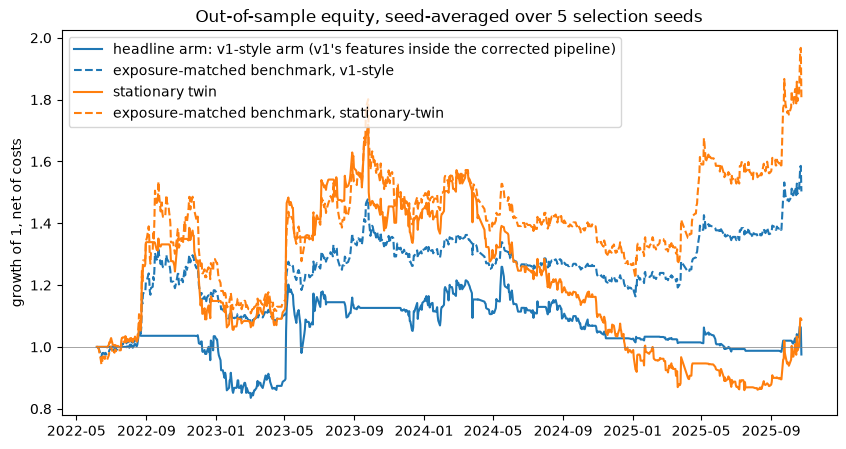

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
for run, color in zip(PRIMARY_PAIR, ["C0", "C1"]):
    r = a.per_seed(series, trades, run, settings).mean(axis=1)
    ax.plot((1 + r).cumprod(), color=color, label=LABELS[run])
    matched = exposure_matched_benchmark(bench, a.position(series, run))
    ax.plot((1 + matched).cumprod(), color=color, ls="--", label=f"exposure-matched benchmark, {run.replace('_', '-')}")
ax.axhline(1, color="grey", lw=0.5)
ax.set(title=f"Out-of-sample equity, seed-averaged over {len(settings.selection_seeds)} selection seeds", ylabel="growth of 1, net of costs")
ax.legend()
fig.savefig(RESULTS / "headline.png", dpi=150, bbox_inches="tight")

## Headline table and the readings

Primary pair, seed-averaged series, default costs. Risk-free rate zero.

In [4]:
headline = rows(PRIMARY_PAIR)
fmt(headline)

,strategy return,Sharpe [95% CI],"excess, bps/day [95% CI]","break-even, bps round trip",trades per seed,"per-seed Sharpe, mean (min to max)"
v1_style,-2.5%,"0.08 [-1.01, 0.99]","-4.97 [-12.37, +2.45]",None,26.8,0.06 (-0.19 to 0.40)
stationary_twin,+8.8%,"0.23 [-0.90, 1.21]","-6.01 [-13.60, +1.48]",15,57.4,0.20 (-0.05 to 0.49)


In [5]:
r1 = a.reading1(a.per_seed(series, trades, "v1_style", settings),
                a.per_seed(series, trades, "stationary_twin", settings), settings)
# Reading 2: neither arm's whole-series excess-return CI lies above zero.
r2 = not any(lo > 0 for lo, _ in headline.excess_ci)
lo, hi = r1["diff_ci"]
print(f"""Reading 1 (two-sided), v1-style minus stationary twin:
  gate 1, paired {CI} on the daily return difference: [{lo * 1e4:+.2f}, {hi * 1e4:+.2f}] bps -> {'pass' if r1['gate1'] else 'fail'}
  gate 2, gap in mean per-seed Sharpe {r1['sharpe_gap']:+.2f} against selection spread {r1['selection_spread']:.2f} -> {'pass' if r1['gate2'] else 'fail'}
  outcome: {r1['outcome']}
Reading 2 (the strategy never worked): {'holds' if r2 else 'does not hold'}""")

Reading 1 (two-sided), v1-style minus stationary twin:
  gate 1, paired 95% CI on the daily return difference: [-12.29, +7.30] bps -> fail
  gate 2, gap in mean per-seed Sharpe -0.14 against selection spread 0.59 -> fail
  outcome: inconclusive
Reading 2 (the strategy never worked): holds


### B10 cross-check

Excess return recomputed with costs at each reported break-even is zero.

In [6]:
for run in list(ARMS) + [f"{r}_meta" for r in PRIMARY_PAIR] + ["buy_and_hold", "momentum", "mean_reversion"]:
    be = a.summary(series, trades, run, settings)["break_even"]
    if be is None or not np.isfinite(be):
        print(f"{run}: break-even {be}, nothing to check")
        continue
    excess = a.summary(series, trades, run, settings, round_trip_bps=be)["excess"]
    assert abs(excess) < 1e-12, (run, be, excess)
    print(f"{run}: excess at {be:.1f} bps = {excess:.1e}")

v1_style: break-even None, nothing to check


stationary_twin: excess at 14.5 bps = 6.8e-20


clustered_level: break-even None, nothing to check


clustered_stationary: excess at 4.2 bps = -3.4e-20


v1_style_meta: break-even None, nothing to check


stationary_twin_meta: break-even None, nothing to check


buy_and_hold: excess at 13.9 bps = 1.5e-20


momentum: excess at 403.2 bps = -6.8e-20


mean_reversion: break-even None, nothing to check


## Per window

Compounded strategy, exposure-matched benchmark (each window's own average position) and their difference, per test window. Not tested.

Reading 3 (descriptive, no test, primary pair only): an arm beats its exposure-matched benchmark in the early windows and trails it in the late ones, measured by mean daily excess return. A window belongs to the side of the reading-3 boundary that holds most of its test days.

In [7]:
test_windows = windows[windows.run == "v1_style"].drop_duplicates("test_start")
window_tables, reading3 = {}, {}
for run in ARMS:
    r, pos = a.per_seed(series, trades, run, settings).mean(axis=1), a.position(series, run)
    t = a.per_window(r, pos, bench, test_windows, settings)
    window_tables[run] = t[["strategy", "benchmark", "excess"]].map("{:+.1%}".format)
    if run in PRIMARY_PAIR:
        reading3[run] = a.reading3(r, pos, bench, test_windows, settings)
pd.concat({"window": t[["test_start", "test_end", "side"]], **window_tables}, axis=1)

window                   v1_style                   stationary_twin  \
  test_start   test_end   side strategy benchmark  excess        strategy   
1 2022-06-06 2022-11-21  early    +3.6%     +5.2%   -1.6%          +37.6%   
2 2022-11-22 2023-05-23  early    +6.1%    -11.8%  +17.9%           -1.6%   
3 2023-05-24 2023-11-17  early    +2.5%     +5.2%   -2.8%           +9.8%   
4 2023-11-20 2024-05-31   late    +2.3%     -4.7%   +7.0%          -12.4%   
5 2024-06-03 2024-11-20   late   -10.8%     -9.4%   -1.4%          -19.6%   
6 2024-11-21 2025-06-05   late    -1.8%     +4.7%   -6.5%          -11.3%   
7 2025-06-10 2025-10-24   late    -3.4%     +2.4%   -5.8%          +17.2%   

                    clustered_level                   clustered_stationary  \
  benchmark  excess        strategy benchmark  excess             strategy   
1    +25.6%  +12.0%          +15.5%    +17.6%   -2.1%                +6.4%   
2    -10.1%   +8.5%           +4.8%    -11.8%  +16.6%                -0.0%   
3     +7.7%   +2.2%           -0.4%     +0.8%   -1.2%               +15.8%   
4     -5.5%   -7.0%          -15.6%     -6.1%   -9.5%               -13.2%   
5    -12.8%   -6.9%          -19.7%    -13.2%   -6.5%               -12.3%   
6    +22.6%  -33.9%           +6.6%    +12.2%   -5.6%                +3.5%   
7    +12.8%   +4.4%          -17.4%     +2.6%  -20.0%                +8.4%   

                     
  benchmark  excess  
1    +20.7%  -14.3%  
2    -11.0%  +10.9%  
3     +6.4%   +9.4%  
4     -5.6%   -7.7%  
5    -13.2%   +0.9%  
6    +22.6%  -19.1%  
7    +10.1%   -1.7%

In [8]:
pd.DataFrame({run: {"early, bps/day": f"{d['early'] * 1e4:+.2f}", "late, bps/day": f"{d['late'] * 1e4:+.2f}",
                    "reading 3 pattern": "yes" if d["holds"] else "no"} for run, d in reading3.items()}).T

,"early, bps/day","late, bps/day",reading 3 pattern
v1_style,+4.21,-1.18,yes
stationary_twin,+6.54,-9.57,yes


## Price only, early and late

Cost-free buy-and-hold over the out-of-sample series, split at the reading-3 boundary. This table goes in the README whatever the models show.

In [9]:
p = a.price_only(series, settings)
p.assign(**{"return": p["return"].map("{:+.1%}".format), "volatility": p.volatility.map("{:.0%}".format),
            "sharpe": p.sharpe.map("{:.2f}".format)})

,start,end,return,volatility,sharpe
early,2022-06-06,2023-12-29,+72.1%,53%,0.92
late,2024-01-02,2025-10-24,+30.5%,37%,0.61
calendar 2024,2024-01-02,2024-12-30,-23.0%,25%,-0.98


## Cost stresses

Primary pair, recomputed from gross returns and trade dates (costs never change a decision), keeping the sell-side gap.

In [10]:
costs = [settings.buy_cost_bps + settings.sell_cost_bps] + [b + s for b, s in settings.cost_stresses]
pd.concat({f"{c:.0f} bps": fmt(rows(PRIMARY_PAIR, c)) for c in costs}).drop(columns="break-even, bps round trip")

strategy return      Sharpe [95% CI]  \
100 bps v1_style                  -2.5%   0.08 [-1.01, 0.99]   
        stationary_twin           +8.8%   0.23 [-0.90, 1.21]   
150 bps v1_style                 -14.7%  -0.11 [-1.22, 0.82]   
        stationary_twin          -18.4%  -0.05 [-1.19, 0.93]   
200 bps v1_style                 -25.5%  -0.29 [-1.42, 0.67]   
        stationary_twin          -38.8%  -0.34 [-1.49, 0.66]   

                        excess, bps/day [95% CI] trades per seed  \
100 bps v1_style           -4.97 [-12.37, +2.45]            26.8   
        stationary_twin    -6.01 [-13.60, +1.48]            57.4   
150 bps v1_style           -6.61 [-13.99, +0.82]            26.8   
        stationary_twin    -9.53 [-17.09, -2.12]            57.4   
200 bps v1_style           -8.26 [-15.64, -0.81]            26.8   
        stationary_twin   -13.05 [-20.62, -5.60]            57.4   

                        per-seed Sharpe, mean (min to max)  
100 bps v1_style                      0.06 (-0.19 to 0.40)  
        stationary_twin               0.20 (-0.05 to 0.49)  
150 bps v1_style                     -0.10 (-0.35 to 0.25)  
        stationary_twin              -0.06 (-0.34 to 0.26)  
200 bps v1_style                     -0.27 (-0.51 to 0.11)  
        stationary_twin              -0.32 (-0.63 to 0.04)

## Meta-labelling ablation

Primary pair, each base run beside its meta-labelled run. A window whose out-of-fold predictions had no +1 call trades as the base run does (Amendment 2).

In [11]:
fmt(rows([r for base in PRIMARY_PAIR for r in (base, f"{base}_meta")]))

,strategy return,Sharpe [95% CI],"excess, bps/day [95% CI]","break-even, bps round trip",trades per seed,"per-seed Sharpe, mean (min to max)"
v1_style,-2.5%,"0.08 [-1.01, 0.99]","-4.97 [-12.37, +2.45]",None,26.8,0.06 (-0.19 to 0.40)
v1_style_meta,-15.0%,"-0.26 [-1.18, 0.63]","-5.62 [-11.30, -0.08]",None,29.6,-0.25 (-0.64 to -0.01)
stationary_twin,+8.8%,"0.23 [-0.90, 1.21]","-6.01 [-13.60, +1.48]",15,57.4,0.20 (-0.05 to 0.49)
stationary_twin_meta,-31.6%,"-0.49 [-1.55, 0.45]","-9.51 [-16.22, -3.54]",None,56.4,-0.41 (-0.92 to -0.06)


In [12]:
meta = windows[windows.run.str.endswith("_meta")]
meta.groupby("run").oof_long_calls.agg(windows="size", fallback_windows=lambda c: int((c == 0).sum()),
                                       median_oof_long_calls="median")

,windows,fallback_windows,median_oof_long_calls
run,,,
stationary_twin_meta,35,0,205.0
v1_style_meta,35,0,88.0


## Secondary pair, descriptive

Every feature, lags included, goes through clustering. No gates.

In [13]:
fmt(rows(["clustered_level", "clustered_stationary"]))

,strategy return,Sharpe [95% CI],"excess, bps/day [95% CI]","break-even, bps round trip",trades per seed,"per-seed Sharpe, mean (min to max)"
clustered_level,-28.0%,"-0.25 [-1.51, 0.83]","-9.54 [-19.09, +0.15]",None,35.0,-0.25 (-0.25 to -0.25)
clustered_stationary,+5.2%,"0.20 [-0.79, 1.03]","-6.22 [-16.03, +3.02]",4,53.0,0.20 (0.20 to 0.20)


## Baselines

Through the same trade simulator and default costs. Each is a single run, so trades per seed is its trade count.

In [14]:
fmt(rows(["buy_and_hold", "momentum", "mean_reversion"])).drop(columns="per-seed Sharpe, mean (min to max)")

,strategy return,Sharpe [95% CI],"excess, bps/day [95% CI]","break-even, bps round trip",trades per seed
buy_and_hold,+122.1%,"0.76 [-0.31, 1.71]","-0.11 [-0.37, +0.03]",14,1.0
momentum,+107.2%,"0.75 [-0.38, 1.67]","+4.83 [-4.42, +14.41]",403,13.0
mean_reversion,-14.3%,"-0.63 [-1.47, 0.21]","-2.64 [-5.16, -0.25]",None,6.0
